In [1]:
source('../../../R/preamble.R')

freqplot = function(df, spacing = 0.00){
    ggplot(df) + aes(gen, freq + spacing*dense_rank(pos), col = pos, group = tid) + 
    geom_line() + geom_point(size = 0.3) +
    #scale_x_continuous(breaks = 0:16) +
    facet_wrap(~pop, ncol = 4) +
    labs(x = 'Generation', y = 'Frequency')
    }

fpop = function(n = 5) facet_wrap(~pop, ncol = n)

conf = 0.95

In [2]:
d = read.tsv('../../../datasets/genomics/05_genome_mapping/results/d_aff.tsv')

tid_to_mutator_bg = read.tsv('../../../datasets/genomics/06_mutators/results/tid_to_mutator_bg.tsv')

v = read.tsv('../../../datasets/genomics/04_gene_attribution/results/v.tsv') %>% left_join(tid_to_mutator_bg)

Joining with `by = join_by(pop, tid)`


# Plot fhuA waves

In [3]:
cultures = c('A', 'B', 'C', 'D', 'F')

fhuA_freqs =
d %>%
    filter(context == 'fhuA', nchar(pop) == 1, pop %in% cultures) %>% 
    group_by(pop, gen) %>%
    mutate(total_freq = sum(freq), f = ifelse(total_freq > 1, freq / total_freq, freq)) %>% # sometimes freqs sum up to slightly >1
    ungroup()

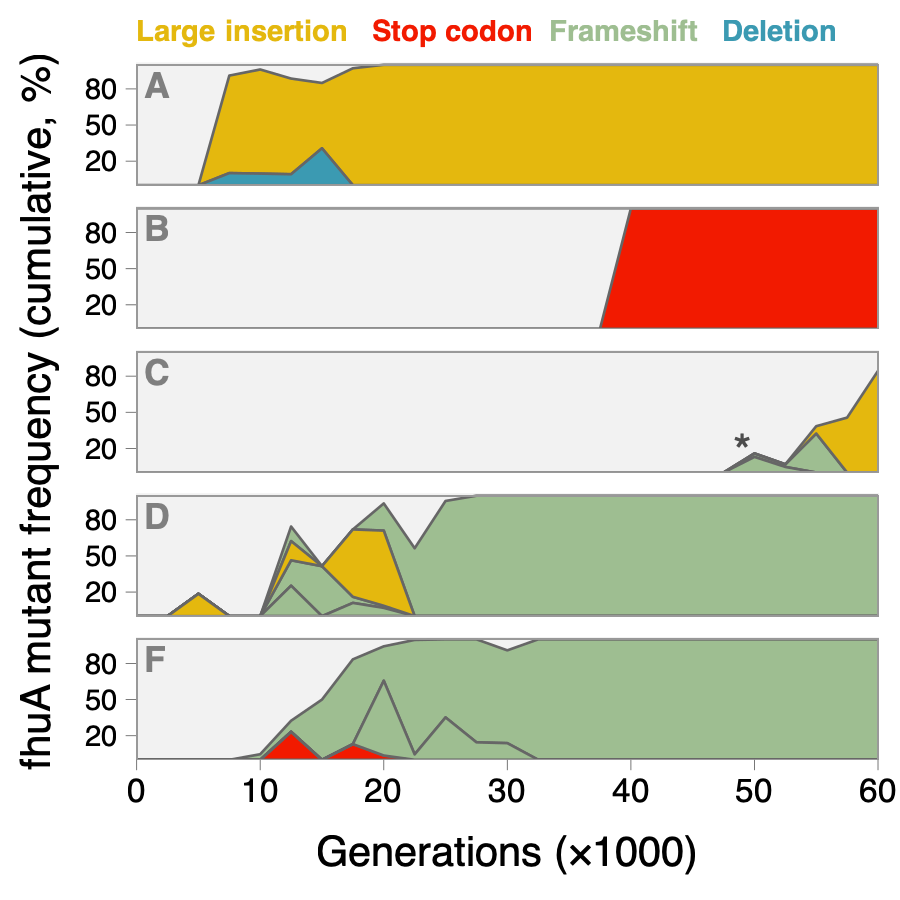

In [4]:
labels = c('aa_indel'='Deletion', 'frameshift'='Frameshift', 'large_insertion'='Large insertion', 'nonsense'='Stop codon')
lwd = 0.3
legend_size = 5
grey = 'grey40'

size(3,3)

letters = tibble(pop=cultures, gen=0.25, y=94, ymin=1, ymax=1, label='Frameshift', vid=NA)
mutant_labels = tribble(
    ~pop, ~gen, ~y, ~label,
    'A', 20/2.5, 50, 'Large insertion',
    'B', 45/2.5, 50, 'Stop codon',
    'D', 27/2.5, 50, 'Frameshift',
    'F', 22/2.5, 62, 'Frameshift'
    ) %>% 
    mutate(ymin=NA, ymax=NA, vid=NA)

# Legend: each type of mutation written in its colour (the colours of the default fill scale)
fhuA_colors = setNames(pal_adaptive(Zissou1)(4), c('Deletion', 'Frameshift', 'Large insertion', 'Stop codon'))
legend_order = c('Large insertion', 'Stop codon', 'Frameshift', 'Deletion')
legend_text = paste0("<span style='color:", substr(fhuA_colors[legend_order], 1, 7), "'>", legend_order, "</span>", collapse = '\u2003\u2003')

fhuA_freqs %>%
    select(pop, gen, f, cat, vid, max_f) %>%
    arrange(pop, max_f) %>%
    group_by(pop, gen) %>%
    mutate(
        ymax = cumsum(f),
        ymin = ymax - f,
        label=labels[cat]
    ) %>%
    ungroup() %>% 

ggplot() + aes(gen*2.5, min=ymin*100, max=ymax*100, fill=label, group=vid) +

    coord_cartesian(xlim=c(-0.05, 60.1), ylim=c(0, 102), expand = 0) +
    scale_y_continuous(breaks = seq(20, 80, 30)) +

    facet_wrap(~pop, ncol=1) + 

    geom_ribbon(col=grey, lwd=lwd) +
    scale_fill_manual(values = fhuA_colors) +

    # Bounding box
    geom_rect(xmin = 0, xmax = 60, ymin = 0, ymax = 100, fill = NA, col = 'grey60', lwd = lwd/2) +

    # Lineage letters
    geom_text(data=letters, aes(y=y, label=pop), size=3, fontface='bold', hjust=0, vjust=1, col='grey50') +


    # Collapse event
    geom_text(
        data=tibble(gen=49/2.5, y=18, star='*', label=NA, ymin=NA, ymax=NA, vid=NA, pop = 'C'),
        aes(y=y, label=star),
        size=4, col='grey30'
    ) +

    theme(
        strip.text=eb,
        axis.line = eb, panel.grid = eb, axis.text.y = element_text(size=7),
        panel.background = element_rect(fill='grey95'),
        legend.key.size = unit(10, "pt"), 
        legend.key.spacing.y = unit(5, "pt"),
        legend.text = element_text(size = legend_size),
        legend.title = element_text(size = legend_size, face = 'bold'),
        strip.background = eb,
        plot.title = ggtext::element_markdown(size = 7, face = 'bold', hjust = 0, margin = margin(0, 0, 3, 0)),
    ) +

    labs(x = 'Generations (×1000)', y = 'fhuA mutant frequency (cumulative, %)', fill = 'FhuA mutants:', title = legend_text) + nl

psave('Plots/fhuA_alleles_areas_1_col')